# Atlas-DeePC on additional compact robotic tasks

This notebook tests **Atlas-DeePC** and **contextual Atlas-DeePC** beyond Reacher while preserving the central data-driven controller: every predicted input-output trajectory is an affine linear combination of columns of a cached SVD basis of offline Hankel data. No fitted dynamics model, inverse kinematics controller, feedback fallback, or offline action replay is used.

The configurations are task-specific. This matters: a dissipative point mass, unstable balance problem, energy-building swing-up, and contact task should not be expected to share one horizon, rank, exploration spectrum, or contextual trigger.

**Held-out result snapshot**

| Task | Atlas-DeePC | Contextual Atlas-DeePC | Interpretation |
|---|---:|---:|---|
| PointMass Easy | 20/20 | 20/20 | solved |
| Cartpole Balance | 8/20 | 20/20 | contextual charts repair local model selection |
| Pendulum Swingup | 10/10 | 10/10 | solved by coherent graph-path references |
| Finger Turn Easy | 3/10 | 3/10 | contact acquisition remains brittle |
| Ball-in-Cup | 1/3 | 1/3 | one sustained catch; pilot-sized stress test |
| Cartpole Swingup | 0/3 | 0/3 | unresolved energy acquisition stress test |

The 3-seed panels are diagnostic pilots, not statistically credible success-rate estimates.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/atlas_deepc_mpl')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
RESULT_ROOT = ROOT / 'experiments' / 'simple_robot_atlas_profiles'
TASK_ORDER = [
    'point_mass_easy',
    'cartpole_balance',
    'pendulum_swingup',
    'finger_turn_easy',
    'ball_in_cup',
    'cartpole_swingup',
]
TASK_LABELS = {
    'point_mass_easy': 'PointMass',
    'cartpole_balance': 'Cartpole\nBalance',
    'pendulum_swingup': 'Pendulum\nSwingup',
    'finger_turn_easy': 'Finger\nTurn',
    'ball_in_cup': 'Ball-in-Cup',
    'cartpole_swingup': 'Cartpole\nSwingup',
}
METHOD_LABELS = {
    'atlas': 'Atlas-DeePC',
    'contextual_atlas': 'Contextual Atlas-DeePC',
}
COLORS = {'atlas': '#0072B2', 'contextual_atlas': '#D55E00'}

summaries = {}
for task in TASK_ORDER:
    path = RESULT_ROOT / task / 'summary.json'
    assert path.exists(), path
    summaries[task] = json.loads(path.read_text())

print('Loaded:', ', '.join(TASK_LABELS[task].replace('\n', ' ') for task in TASK_ORDER))
print('Result root:', RESULT_ROOT)

Loaded: PointMass, Cartpole Balance, Pendulum Swingup, Finger Turn, Ball-in-Cup, Cartpole Swingup
Result root: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/simple_robot_atlas_profiles


## 1. What changes between tasks

The controller class and DeePC QP are shared. The table below records the parts that legitimately depend on task mechanics:

- **Exploration** controls which dynamics the random offline library excites.
- **$T_f$ and rank** control predictive reach and local behavioral complexity.
- **Reference mode** is either the exact final goal, ordinary chart waypoints, an observed edge sequence, or a coherent goal-reaching path through offline chart transitions.
- **Context activation** is always-on for local balancing, stalled-progress-triggered for Reacher-like/contact tasks, goal-basin-latched for Pendulum, and enabled only after a strict upright dwell in the Cartpole swing-up stress test.

In [2]:
profile_rows = []
for task in TASK_ORDER:
    summary = summaries[task]
    cfg = summary['config']
    audit = summary['offline_audit']
    atlas = summary['offline_atlas']
    profile_rows.append({
        'task': TASK_LABELS[task].replace('\n', ' '),
        'held-out seeds': f"{audit['online_eval_seed_range'][0]}-{audit['online_eval_seed_range'][1]}",
        'random offline policy': audit['collection_policy'],
        'episodes x steps': f"{cfg['offline_episodes']} x {cfg['offline_steps']}",
        'Tf': cfg['t_f'],
        'charts': cfg['clusters'],
        'rank cap': cfg['svd_rank'],
        'reference': cfg['reference_mode'],
        'context activation': cfg['contextual_activation'],
    })
display(pd.DataFrame(profile_rows).set_index('task'))

,held-out seeds,random offline policy,episodes x steps,Tf,charts,rank cap,reference,context activation
task,,,,,,,,
PointMass,601-620,"reset=task_default, uniform_ar: a=0.9, b=0.3, ...",200 x 200,10,4,29,final,triggered
Cartpole Balance,601-620,"reset=task_default, uniform_ar: a=0.9, b=0.3, ...",60 x 400,10,16,16,final,always
Pendulum Swingup,601-610,"reset=task_default, square: a=0, b=1, hold=1, ...",100 x 500,20,48,60,goal_path,latched
Finger Turn,601-610,"reset=task_default, uniform_ar: a=0, b=1, hold...",200 x 200,10,48,60,graph_routed,triggered
Ball-in-Cup,601-603,"reset=task_default, uniform_ar: a=0, b=1, b_lo...",100 x 400,20,48,100,edge_sequence,triggered
Cartpole Swingup,601-603,"reset=blocked_near_goal, mixed: a=0.9, b=1, b_...",200 x 480,30,48,100,template_path,successful


### Temporally coherent chart paths

Static chart medoids work well for slow Reacher motion but discard phase and momentum. For Pendulum, each physical chart $C_k$ instead stores a future output prefix from an actual random-data suffix that later enters the upright basin:

$$
r_k^{\mathrm{path}}
=
\left[Y_f(:,i_k)\right],
\qquad
i_k\in C_k,
\qquad
\exists\tau>0:\; y_{i_k+\tau}\in\mathcal G.
$$

At time $t$, the current output localizes chart $k_t$ and DeePC tracks $r_{k_t}^{\mathrm{path}}$. Only the **output sequence** is a reference. The corresponding offline inputs are never replayed. The optimized trajectory still obeys

$$
\begin{bmatrix}u_{\rm ini}\\u\\y_{\rm ini}+\sigma\\y\end{bmatrix}
=\bar h_{k_t}+B_{k_t}g,
$$

with the same input bounds and quadratic DeePC objective. This preserves momentum-building transitions that a stitched list of independent medoids loses.

In [3]:
path_rows = []
for task in TASK_ORDER:
    summary = summaries[task]
    atlas = summary['offline_atlas']
    path_rows.append({
        'task': TASK_LABELS[task].replace('\n', ' '),
        'Hankel shape': str(tuple(atlas['hankel_shape'])),
        'chart size min': atlas['chart_size_min'],
        'chart size median': atlas['chart_size_median'],
        'retained graph edges': atlas['retained_edges'],
        'charts with coherent path': atlas.get('charts_with_coherent_goal_paths', 'not recorded'),
        'physical rank': f"{atlas['physical_rank_min']}-{atlas['physical_rank_max']}",
        'context prototypes': atlas['contextual_prototypes'],
    })
display(pd.DataFrame(path_rows).set_index('task'))

,Hankel shape,chart size min,chart size median,retained graph edges,charts with coherent path,physical rank,context prototypes
task,,,,,,,
PointMass,"(72, 37800)",8090,9679.5,11,not recorded,29-29,64
Cartpole Balance,"(72, 23340)",720,1453.5,74,not recorded,16-16,128
Pendulum Swingup,"(88, 47900)",539,787.0,179,22,60-60,128
Finger Turn,"(132, 37800)",277,752.0,277,not recorded,60-60,256
Ball-in-Cup,"(220, 37900)",299,758.5,647,48,100-100,128
Cartpole Swingup,"(192, 89800)",328,843.0,352,48,100-100,512


## 2. Paired held-out outcomes

In [4]:
records = []
for task in TASK_ORDER:
    summary = summaries[task]
    threshold = summary['task_spec']['success_threshold']
    for method in METHOD_LABELS:
        result = summary[method]
        records.append({
            'task_key': task,
            'task': TASK_LABELS[task].replace('\n', ' '),
            'method_key': method,
            'method': METHOD_LABELS[method],
            'successes': result['successes'],
            'trials': result['trials'],
            'success rate (%)': 100 * result['successes'] / result['trials'],
            'median tail / threshold': result['median_last_100'] / threshold,
            'median tail error': result['median_last_100'],
        })
results = pd.DataFrame(records)
display(results[['task', 'method', 'successes', 'trials', 'success rate (%)',
                 'median tail / threshold']].set_index(['task', 'method']).round(4))

successes  trials  success rate (%)  \
task             method                                                        
PointMass        Atlas-DeePC                    20      20          100.0000   
                 Contextual Atlas-DeePC         20      20          100.0000   
Cartpole Balance Atlas-DeePC                     8      20           40.0000   
                 Contextual Atlas-DeePC         20      20          100.0000   
Pendulum Swingup Atlas-DeePC                    10      10          100.0000   
                 Contextual Atlas-DeePC         10      10          100.0000   
Finger Turn      Atlas-DeePC                     3      10           30.0000   
                 Contextual Atlas-DeePC          3      10           30.0000   
Ball-in-Cup      Atlas-DeePC                     1       3           33.3333   
                 Contextual Atlas-DeePC          1       3           33.3333   
Cartpole Swingup Atlas-DeePC                     0       3            0.0000   
                 Contextual Atlas-DeePC          0       3            0.0000   

                                         median tail / threshold  
task             method                                           
PointMass        Atlas-DeePC                              0.0017  
                 Contextual Atlas-DeePC                   0.0017  
Cartpole Balance Atlas-DeePC                              1.3783  
                 Contextual Atlas-DeePC                   0.2566  
Pendulum Swingup Atlas-DeePC                              0.0001  
                 Contextual Atlas-DeePC                   0.0003  
Finger Turn      Atlas-DeePC                              2.1798  
                 Contextual Atlas-DeePC                   2.1798  
Ball-in-Cup      Atlas-DeePC                              9.7364  
                 Contextual Atlas-DeePC                   9.6815  
Cartpole Swingup Atlas-DeePC                              7.2703  
                 Contextual Atlas-DeePC                   7.2703

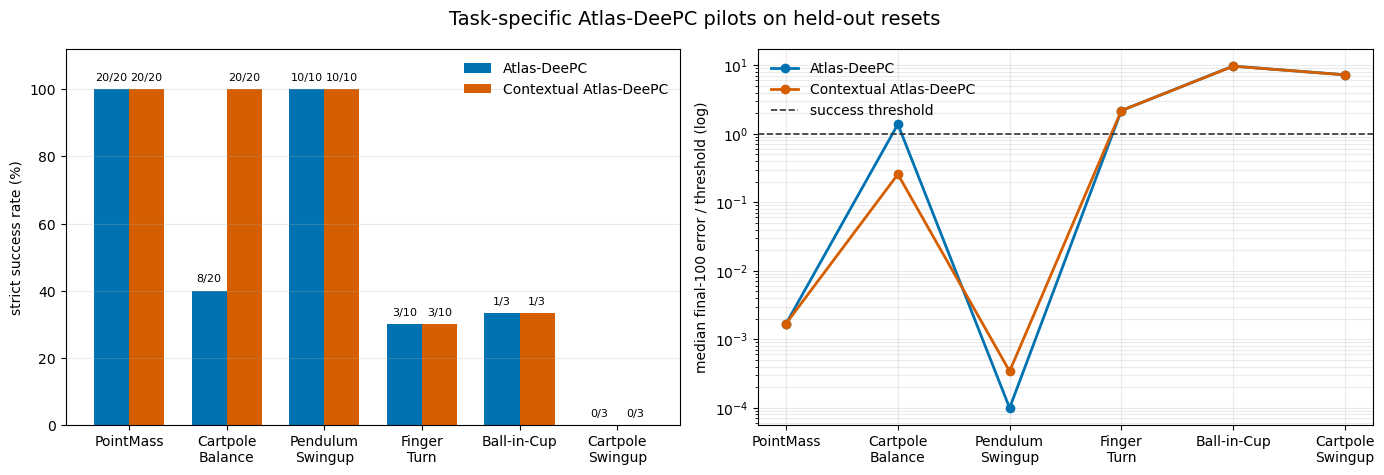

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(TASK_ORDER))
width = 0.36
for offset, method in zip((-width / 2, width / 2), METHOD_LABELS):
    rows = results[results['method_key'] == method].set_index('task_key').loc[TASK_ORDER]
    bars = axes[0].bar(x + offset, rows['success rate (%)'], width,
                       color=COLORS[method], label=METHOD_LABELS[method])
    for bar, successes, trials in zip(bars, rows['successes'], rows['trials']):
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                     f'{int(successes)}/{int(trials)}', ha='center', va='bottom', fontsize=8)
    axes[1].plot(x, rows['median tail / threshold'], 'o-', linewidth=2,
                 markersize=6, color=COLORS[method], label=METHOD_LABELS[method])

axes[0].set_ylabel('strict success rate (%)')
axes[0].set_ylim(0, 112)
axes[0].set_xticks(x, [TASK_LABELS[t] for t in TASK_ORDER])
axes[0].legend(frameon=False, loc='upper right')
axes[0].grid(axis='y', alpha=0.25)

axes[1].axhline(1.0, color='#333333', linestyle='--', linewidth=1.2,
                label='success threshold')
axes[1].set_yscale('log')
axes[1].set_ylabel('median final-100 error / threshold (log)')
axes[1].set_xticks(x, [TASK_LABELS[t] for t in TASK_ORDER])
axes[1].grid(alpha=0.25, which='both')
axes[1].legend(frameon=False, loc='best')
fig.suptitle('Task-specific Atlas-DeePC pilots on held-out resets', fontsize=14)
fig.tight_layout()
plt.show()

## 3. Representative closed-loop traces

Errors are normalized by each task's strict threshold. Values below the dashed line satisfy the instantaneous criterion; strict success additionally requires both the final-30 and final-100 means to remain below it.

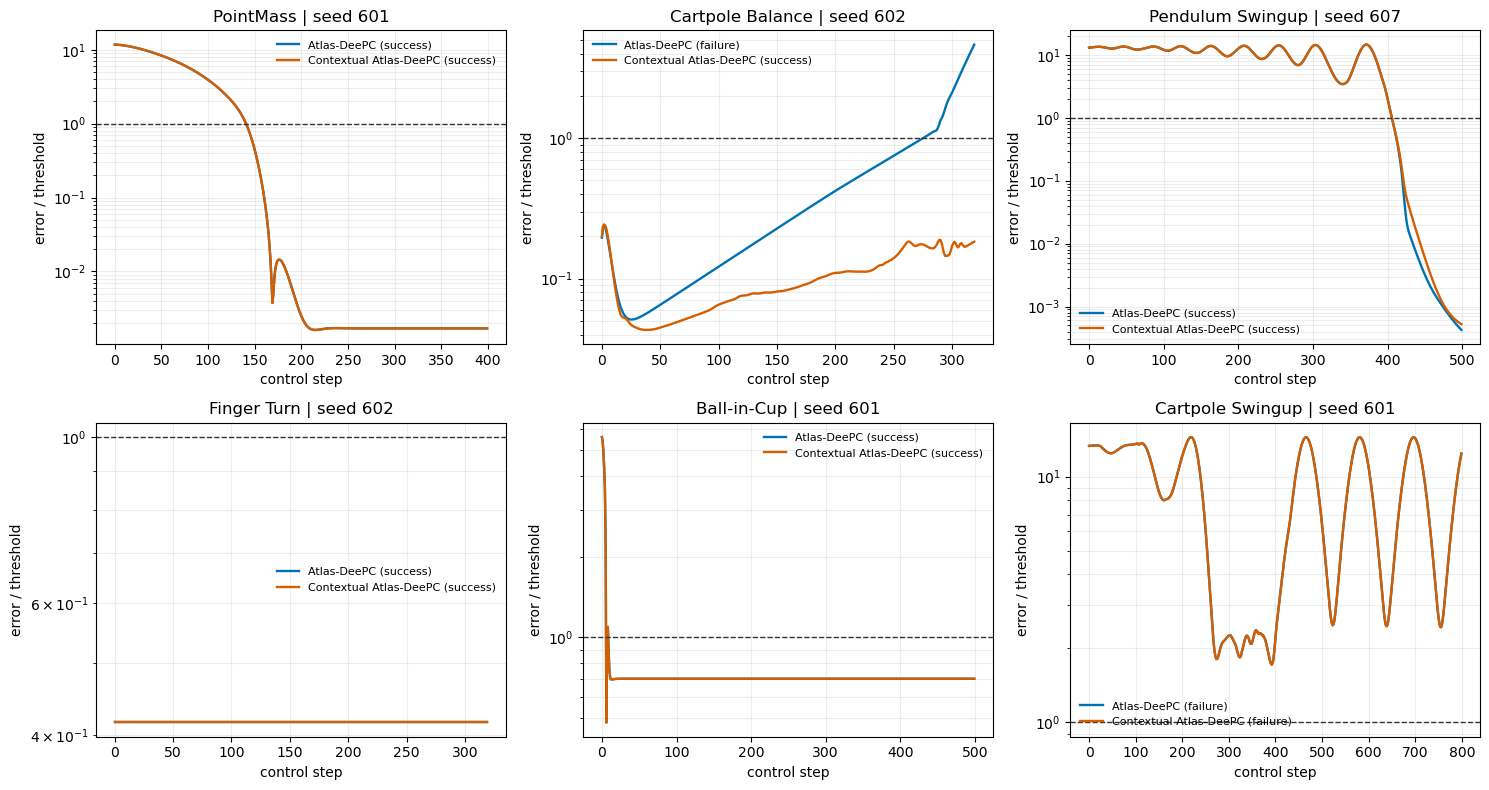

In [6]:
def paired_rows(summary, seed):
    by_key = {(row['method'], int(row['seed'])): row for row in summary['results']}
    return {method: by_key[(method, seed)] for method in METHOD_LABELS}

representative_seed = {
    'point_mass_easy': 601,
    'cartpole_balance': next(
        int(a['seed']) for a in summaries['cartpole_balance']['results']
        if a['method'] == 'atlas' and not a['strict_success'] and any(
            b['method'] == 'contextual_atlas' and int(b['seed']) == int(a['seed'])
            and b['strict_success'] for b in summaries['cartpole_balance']['results']
        )
    ),
    'pendulum_swingup': 607,
    'finger_turn_easy': next(
        int(row['seed']) for row in summaries['finger_turn_easy']['results']
        if row['method'] == 'atlas' and row['strict_success']
    ),
    'ball_in_cup': 601,
    'cartpole_swingup': 601,
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=False)
for task, ax in zip(TASK_ORDER, axes.flat):
    summary = summaries[task]
    threshold = summary['task_spec']['success_threshold']
    seed = representative_seed[task]
    rows = paired_rows(summary, seed)
    for method, row in rows.items():
        normalized = np.maximum(np.asarray(row['errors']) / threshold, 1e-5)
        ax.plot(normalized, color=COLORS[method], linewidth=1.7,
                label=f"{METHOD_LABELS[method]} ({'success' if row['strict_success'] else 'failure'})")
    ax.axhline(1, color='#333333', linestyle='--', linewidth=1)
    ax.set_yscale('log')
    ax.set_title(f"{TASK_LABELS[task].replace(chr(10), ' ')} | seed {seed}")
    ax.set_xlabel('control step')
    ax.set_ylabel('error / threshold')
    ax.grid(alpha=0.22, which='both')
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 4. Online computation by module

,QP solve,routing,chart selection,environment,other loop,total
label,,,,,,
PointMass\nAtlas-DeePC,25.079,0.027,0.001,0.152,0.029,25.288
PointMass\nContextual Atlas-DeePC,25.062,0.027,0.001,0.153,0.044,25.285
Cartpole Balance\nAtlas-DeePC,24.248,0.026,0.001,0.186,0.019,24.479
Cartpole Balance\nContextual Atlas-DeePC,24.752,0.026,0.042,0.187,0.020,25.028
Pendulum Swingup\nAtlas-DeePC,50.691,0.033,0.001,0.128,0.006,50.859
Pendulum Swingup\nContextual Atlas-DeePC,52.204,0.033,0.042,0.127,0.032,52.439
Finger Turn\nAtlas-DeePC,35.375,0.284,0.001,0.179,0.112,35.951
Finger Turn\nContextual Atlas-DeePC,34.975,0.363,0.075,0.179,0.262,35.854
Ball-in-Cup\nAtlas-DeePC,76.525,2.627,0.001,0.174,0.032,79.359


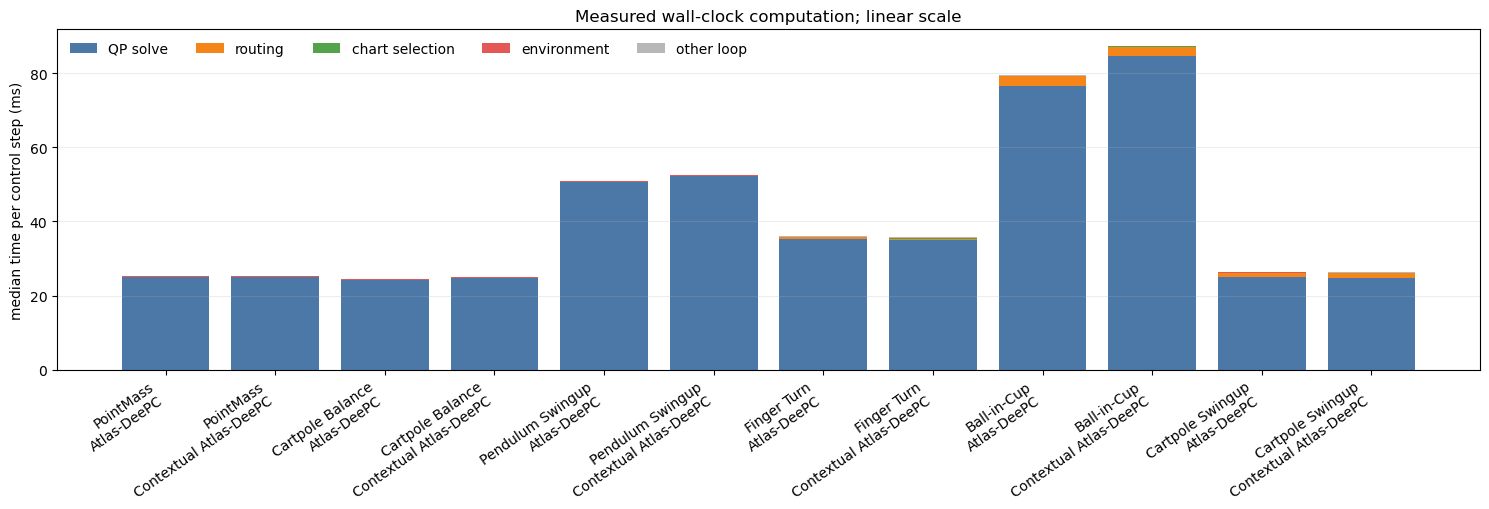

In [7]:
timing_rows = []
for task in TASK_ORDER:
    summary = summaries[task]
    for method in METHOD_LABELS:
        row = summary[method]
        known = (
            row['median_solve_ms'] + row.get('median_routing_ms', 0)
            + row.get('median_selection_ms', 0) + row.get('median_environment_ms', 0)
        )
        timing_rows.append({
            'task_key': task,
            'method_key': method,
            'label': f"{TASK_LABELS[task].replace(chr(10), ' ')}\n{METHOD_LABELS[method]}",
            'QP solve': row['median_solve_ms'],
            'routing': row.get('median_routing_ms', 0),
            'chart selection': row.get('median_selection_ms', 0),
            'environment': row.get('median_environment_ms', 0),
            'other loop': max(0, row.get('median_control_step_ms', known) - known),
            'total': row.get('median_control_step_ms', known),
        })
timing = pd.DataFrame(timing_rows)
display(timing[['label', 'QP solve', 'routing', 'chart selection',
                'environment', 'other loop', 'total']].set_index('label').round(3))

fig, ax = plt.subplots(figsize=(15, 5.2))
positions = np.arange(len(timing))
bottom = np.zeros(len(timing))
module_colors = {
    'QP solve': '#4C78A8',
    'routing': '#F58518',
    'chart selection': '#54A24B',
    'environment': '#E45756',
    'other loop': '#B8B8B8',
}
for module, color in module_colors.items():
    values = timing[module].to_numpy()
    ax.bar(positions, values, bottom=bottom, color=color, label=module)
    bottom += values
ax.set_ylabel('median time per control step (ms)')
ax.set_xticks(positions, timing['label'], rotation=35, ha='right')
ax.grid(axis='y', alpha=0.22)
ax.legend(frameon=False, ncol=5, loc='upper left')
ax.set_title('Measured wall-clock computation; linear scale')
fig.tight_layout()
plt.show()

The QP dominates every task. Routing and prototype scoring remain sub-millisecond for PointMass, Balance, and Pendulum; contact tasks spend a few milliseconds routing because their graph and output dimensions are larger. These timings are machine-specific and are not hard real-time guarantees.

## 5. Offline-data fairness audit

In [8]:
audit_rows = []
for task in TASK_ORDER:
    summary = summaries[task]
    audit = summary['offline_audit']
    assert audit['stabilized_episodes_in_offline_data'] == 0
    assert audit['online_offline_seed_disjoint']
    audit_rows.append({
        'task': TASK_LABELS[task].replace('\n', ' '),
        'accepted random episodes': audit['accepted_episode_count'],
        'rejected stabilized episodes': audit['rejected_stabilized_episode_count'],
        'retained stabilized episodes': audit['stabilized_episodes_in_offline_data'],
        'offline seeds': str(audit['accepted_seed_range']),
        'evaluation seeds': str(audit['online_eval_seed_range']),
        'seed sets disjoint': audit['online_offline_seed_disjoint'],
        'instantaneous goal samples': audit['offline_samples_below_success_threshold'],
    })
display(pd.DataFrame(audit_rows).set_index('task'))

finger_distances = [
    row['goal_source_target_distance']
    for row in summaries['finger_turn_easy']['results']
    if row['goal_source_target_distance'] is not None
]
print('Finger minimum offline-source / online-target separation:',
      f'{min(finger_distances):.4f} m (required: 0.0600 m)')
print('Fitted dynamics / IK / feedback fallback / offline input replay: none')

,accepted random episodes,rejected stabilized episodes,retained stabilized episodes,offline seeds,evaluation seeds,seed sets disjoint,instantaneous goal samples
task,,,,,,,
PointMass,200,1,0,"[2026, 2226]","[601, 620]",True,250
Cartpole Balance,60,0,0,"[2026, 2085]","[601, 620]",True,1844
Pendulum Swingup,100,0,0,"[2026, 2125]","[601, 610]",True,187
Finger Turn,200,44,0,"[2026, 2269]","[601, 610]",True,752
Ball-in-Cup,100,17,0,"[2026, 2142]","[601, 603]",True,1209
Cartpole Swingup,200,0,0,"[2026, 2225]","[601, 603]",True,3959


Finger minimum offline-source / online-target separation: 0.0718 m (required: 0.0600 m)
Fitted dynamics / IK / feedback fallback / offline input replay: none


For fixed-goal tasks such as balance and swing-up, transient offline visits to the goal neighborhood are allowed; otherwise local goal dynamics could not be represented. The stronger and relevant exclusion is that **no retained offline episode stabilizes at the goal**. Finger has a variable online target, so it additionally enforces at least `0.06 m` separation from the source episode's target.

## 6. What the experiments say

1. **The framework transfers cleanly to dissipative regulation.** PointMass is solved by both methods with a four-chart rank-29 atlas.
2. **Context can matter even without graph travel.** On Cartpole Balance, always-on $[Y_p,Y_f]$ prototype selection raises held-out success from `8/20` to `20/20` at modest selection cost.
3. **A graph node is not enough for dynamic maneuvers.** Pendulum succeeds only after its waypoint becomes a temporally coherent chart path. This is a principled extension of routing: preserve transition phase, then let DeePC choose the action.
4. **Contact remains the hard boundary.** Finger and Ball-in-Cup need contact-mode coverage and acquisition paths that the current random libraries do not provide reliably.
5. **Cartpole Swingup remains unresolved.** A development reset reached error `0.087` and held the pole upright for more than 200 steps, but the cart slowly drifted to a rail. Increasing cart cost, lengthening the local horizon, filtering prediction bias, and selecting a lower-velocity random template did not produce an 800-step stabilization. On the three untouched resets, the best instantaneous errors are `0.209`--`0.258`; none enters the strict contextual handoff condition. These are failures, not softened successes.

The most convincing additional benchmark today is **Pendulum Swingup**: both methods achieve `10/10` on untouched seeds, using only random open-loop data and cached behavioral bases. The contact tasks and Cartpole Swingup are valuable stress tests that expose where Atlas routing still needs work.

## 7. Reproduction

The frozen task profiles live in `src/run_simple_robot_profiles.py`; the shared benchmark implementation is `src/simple_robot_atlas_benchmark.py`. To rerun an arbitrary held-out range:

```bash
conda run -n gym-robotics-mujoco python src/run_simple_robot_profiles.py \
  --tasks point_mass_easy,cartpole_balance,pendulum_swingup \
  --methods atlas,contextual_atlas \
  --evaluation-seed-start 701 --evaluation-seeds 20 \
  --output-root experiments/simple_robot_atlas_profiles_recheck
```

Use a fresh output root for a new audit panel. The offline collector signature prevents silently reusing a library created under a different exploration configuration.